In [1]:
!pip install polars
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.7 MB/s eta 0:00:00


In [22]:
import gc
from datetime import timedelta

import numpy as np
import polars as pl
from catboost import CatBoostRegressor, Pool

Загрузчик датафрейма

In [3]:
STREAMING = True


def collect_df(lf: pl.LazyFrame) -> pl.DataFrame:
    """Аккуратный collect, чтобы можно было легко отключить streaming."""
    return lf.collect(engine="streaming" if STREAMING else "in-memory")

## 1. Настройки

In [41]:
PATH = "data/train.parquet"  # замените на путь к данным

HORIZON = 30  # горизонт прогноза, дней

# Окна для признаков: последние N дней
WINDOWS = [7, 14, 32, 60, 90]

# Окна, для которых считаем средний чек / GMV на заказ
RATIO_WINDOWS = [32, 90]

# Колонки, по которым строим агрегаты
AGG_COLS = [
    "gmv",
    "gmv_search",
    "gmv_cat",
    "to_cart",
    "to_ord",
    "searches",
    "search_to_cart",
    "search_to_ord",
    #"cat_to_cart",
    #"cat_to_ord",
    "has_search_to_cart",
    "has_search_to_ord",
    #"has_cat_to_cart",
    #"has_cat_to_ord",
]

MAX_HISTORY_DAYS = max(WINDOWS)

# Сколько снапшотов использовать для обучения. Чем меньше, тем меньше памяти, но меньше данных для модели.
N_TRAIN_SNAPSHOTS = 33  # 33 max

# Шаг между обучающими снапшотами. 7 дней — больше данных, но больше памяти. 14 дней — хороший компромисс.
SNAPSHOT_STEP_DAYS = 7

SEED = 42

## 2. Ленивый датафрейм

In [42]:
lf = (
    pl.scan_parquet(PATH)
    .select(["event_date", "user_id", *AGG_COLS])
    .with_columns([pl.col("event_date").cast(pl.Date)] + [pl.col(c).fill_null(0) for c in AGG_COLS])
)

## 3. Получение крайних дат

In [43]:
bounds = (
    lf.select(
        pl.col("event_date").min().alias("min_date"),
        pl.col("event_date").max().alias("max_date"),
    )
    .pipe(collect_df)
)

min_date = bounds["min_date"][0]
max_date = bounds["max_date"][0]

print("min_date:", min_date)
print("max_date:", max_date)

min_date: 2025-01-01
max_date: 2026-02-13


## 4. Получение списка уникальных пользователей

In [44]:
users = (
    lf.select("user_id")
    .unique()
    .pipe(collect_df)
)

n_users = users.height
print("n_users:", n_users)

n_users: 250000


## 5. Создание набора дат для снапшотов

In [45]:
test_snapshot = max_date - timedelta(days=HORIZON)
valid_snapshot = test_snapshot - timedelta(days=HORIZON)

train_start = min_date + timedelta(days=MAX_HISTORY_DAYS)
train_end = valid_snapshot - timedelta(days=HORIZON)

if train_end < train_start:
    raise ValueError("Недостаточно истории для обучения.")

train_snapshots = (
    pl.date_range(
        start=train_start,
        end=train_end,
        interval=f"{SNAPSHOT_STEP_DAYS}d",
        eager=True,
    )
    .to_list()
)

print("train snapshots cout:", len(train_snapshots))
# Берём последние N_TRAIN_SNAPSHOTS, чтобы не раздувать память
train_snapshots = train_snapshots[-N_TRAIN_SNAPSHOTS:]

print("test_snapshot:", test_snapshot)
print("valid_snapshot:", valid_snapshot)
print("train_snapshots:", train_snapshots)

train snapshots cout: 33
test_snapshot: 2026-01-14
valid_snapshot: 2025-12-15
train_snapshots: [datetime.date(2025, 4, 1), datetime.date(2025, 4, 8), datetime.date(2025, 4, 15), datetime.date(2025, 4, 22), datetime.date(2025, 4, 29), datetime.date(2025, 5, 6), datetime.date(2025, 5, 13), datetime.date(2025, 5, 20), datetime.date(2025, 5, 27), datetime.date(2025, 6, 3), datetime.date(2025, 6, 10), datetime.date(2025, 6, 17), datetime.date(2025, 6, 24), datetime.date(2025, 7, 1), datetime.date(2025, 7, 8), datetime.date(2025, 7, 15), datetime.date(2025, 7, 22), datetime.date(2025, 7, 29), datetime.date(2025, 8, 5), datetime.date(2025, 8, 12), datetime.date(2025, 8, 19), datetime.date(2025, 8, 26), datetime.date(2025, 9, 2), datetime.date(2025, 9, 9), datetime.date(2025, 9, 16), datetime.date(2025, 9, 23), datetime.date(2025, 9, 30), datetime.date(2025, 10, 7), datetime.date(2025, 10, 14), datetime.date(2025, 10, 21), datetime.date(2025, 10, 28), datetime.date(2025, 11, 4), datetime.date(

## 6. Список колонок (без их расчета)

In [46]:
# суммарные значения базовых колонок за W дней (группа 1.1)
sum_base_feature_cols = [
    f"{col}_sum_{w}d"
    for col in AGG_COLS
    for w in WINDOWS
]

# суммарные значения базовых колонок за W дней (группа 1.2)
mean_base_feature_cols = [
    f"{col}_mean_{w}d"
    for col in AGG_COLS
    for w in WINDOWS
]

# число дней с gmv > 0 за W дней (группа 2)
active_feature_cols = [
    f"active_days_{w}d"
    for w in WINDOWS
]

# суммарный GVM, деленный на число заказов за W дней (группа 3)
ratio_feature_cols = [
    f"gmv_per_order_{w}d"
    for w in RATIO_WINDOWS
]

# объединение колонок
feature_cols = (
    sum_base_feature_cols
    + mean_base_feature_cols
    + active_feature_cols
    + ["days_since_last_purchase"]  # число дней с последней покупки
    + ratio_feature_cols
)

# вручную созданные признаки (создаются в make_snapshot) из колонок, указанных выше (группа 4)
extra_feature_cols = [
    # средний GMV на день с покупкой за W дней (группа 4.3)
    "gmv_per_active_day_32",
    "gmv_per_active_day_60",
    "gmv_per_active_day_90"
]

# итоговый набор признаков, которые пойдут в модель
feature_cols += extra_feature_cols

# список колонок, которые будут дозаполнены нулями
fill_cols = sum_base_feature_cols + mean_base_feature_cols + active_feature_cols

print("n_features:", len(feature_cols))

n_features: 111


## 7. Функция создания снапшотов (среза данных для обучения или теста)

In [47]:
def make_snapshot(snapshot_date):
    """
    Строит признаки для всех пользователей на дату snapshot_date.

    Target:
        sum(gmv) за следующие HORIZON дней после snapshot_date.

    Features:
        агрегаты за последние WINDOWS дней до snapshot_date включительно.
    """
    # переменные - границы дат
    snap_lit = pl.lit(snapshot_date)
    hist_start_lit = pl.lit(snapshot_date - timedelta(days=MAX_HISTORY_DAYS))
    future_end_lit = pl.lit(snapshot_date + timedelta(days=HORIZON))

    # Берём только нужный диапазон: история + будущее для таргета
    snap_lf = lf.filter(
        (pl.col("event_date") > hist_start_lit)
        & (pl.col("event_date") <= future_end_lit)
    )

    hist_lf = snap_lf.filter(pl.col("event_date") <= snap_lit)
    future_lf = snap_lf.filter(pl.col("event_date") > snap_lit)

    # выражения для group_by().agg()
    agg_exprs = []

    # Суммы за последние w дней для каждой колонки (группа 1.1 и 1.2)
    for col in AGG_COLS:
        for w in WINDOWS:
            start_lit = pl.lit(snapshot_date - timedelta(days=w))
            agg_exprs.append(
                pl.col(col)
                .filter(pl.col("event_date") > start_lit)
                .sum()
                .alias(f"{col}_sum_{w}d")
            )
            agg_exprs.append(
                pl.col(col)
                .filter(pl.col("event_date") > start_lit)
                .mean()
                .alias(f"{col}_mean_{w}d")
            )

    # Число активных дней с gmv > 0 (группа 2)
    for w in WINDOWS:
        start_lit = pl.lit(snapshot_date - timedelta(days=w))
        agg_exprs.append(
            pl.col("event_date")
            .filter((pl.col("event_date") > start_lit) & (pl.col("gmv") > 0))
            .n_unique()
            .alias(f"active_days_{w}d")
        )

    # затухающий GVM
    for half_life in [7, 14, 30]:
        decay_col = f"gmv_decay_hl{half_life}"
        agg_exprs.append(
            (
                pl.col("gmv")
                * (0.5 ** ((snap_lit - pl.col("event_date")).dt.total_days() / half_life))
            ).sum().alias(decay_col)
        )

    # Дата последней покупки
    agg_exprs.append(
        pl.col("event_date")
        .filter(pl.col("gmv") > 0)
        .max()
        .alias("last_purchase_date")
    )

    # Дополнительные lifetime-признаки
    agg_exprs.extend([
        # дата первой активности в доступной истории
        pl.col("event_date").min().alias("first_activity_date"),
        # дата первой покупки в доступной истории
        pl.col("event_date").filter(pl.col("gmv") > 0).min().alias("first_purchase_date"),
        # суммарный GMV за доступную историю
        pl.col("gmv").sum().alias("lifetime_gmv"),
        # суммарное число заказов за доступную историю
        pl.col("to_ord").sum().alias("lifetime_orders"),
        # число дней с покупками за доступную историю
        pl.col("event_date").filter(pl.col("gmv") > 0).count().alias("total_purchase_days"),
    ])

    # выполнение агрегации
    hist_feat = hist_lf.group_by("user_id").agg(agg_exprs)
    # таргет GMV за следующие 30 дней
    target_feat = future_lf.group_by("user_id").agg(pl.col("gmv").sum().alias("target_30d"))


    # создание выходного датасета
    out = (
        users.lazy()
        # присоединение признаков и таргета ко всем пользователям
        .join(hist_feat, on="user_id", how="left")
        .join(target_feat, on="user_id", how="left")
        # заполнение нулями для неактивных пользователей
        .with_columns(pl.col(fill_cols).fill_null(0))
        # число дней с последней покупки
        .with_columns(
            (snap_lit - pl.col("last_purchase_date"))
            .dt.total_days()
            .alias("days_since_last_purchase")
        )
        .drop("last_purchase_date")
        .with_columns(pl.col("days_since_last_purchase").fill_null(999))

        .with_columns([
            # средний GMV на день с покупкой за W дней (группа 4.3)
            (pl.col("gmv_sum_32d") / pl.col("active_days_32d").clip(lower_bound=1))
            .alias("gmv_per_active_day_32"),

            (pl.col("gmv_sum_60d") / pl.col("active_days_60d").clip(lower_bound=1))
            .alias("gmv_per_active_day_60"),

            (pl.col("gmv_sum_90d") / pl.col("active_days_90d").clip(lower_bound=1))
            .alias("gmv_per_active_day_90"),
        ])
        # суммарный GVM, деленный на число заказов за W дней (группа 3)
        .with_columns([
                (pl.col(f"gmv_sum_{w}d") / pl.col(f"to_ord_sum_{w}d").clip(lower_bound=1))
                .alias(f"gmv_per_order_{w}d")
                for w in RATIO_WINDOWS
        ])
        # таргет
        .with_columns(pl.col("target_30d").fill_null(0))
        .with_columns(pl.col(feature_cols + ["target_30d"]).cast(pl.Float32))
        # срез только нужных колонок
        .select(["user_id", *feature_cols, "target_30d"])
    )

    return collect_df(out)

## 8. Формирование тренировочных срезов

In [48]:
n_features = len(feature_cols)
n_train = len(train_snapshots)

estimated_mb = n_train * n_users * n_features * 4 / (1024 ** 2)
print(f"Estimated X_train size: {estimated_mb:.1f} MB")

X_train = np.empty(
    (n_train * n_users, n_features),
    dtype=np.float32,
)

y_train = np.empty(
    n_train * n_users,
    dtype=np.float32,
)

for i, snap in enumerate(train_snapshots):
    print(f"Processing train snapshot: {snap}")

    df_snap = make_snapshot(snap)

    if df_snap.height != n_users:
        raise ValueError(
            f"Snapshot {snap}: expected {n_users} rows, got {df_snap.height}"
        )

    start = i * n_users
    end = start + n_users

    X_train[start:end, :] = df_snap.select(feature_cols).to_numpy()
    y_train[start:end] = df_snap.get_column("target_30d").to_numpy()

    del df_snap
    gc.collect()

Estimated X_train size: 3493.3 MB
Processing train snapshot: 2025-04-01
Processing train snapshot: 2025-04-08
Processing train snapshot: 2025-04-15
Processing train snapshot: 2025-04-22
Processing train snapshot: 2025-04-29
Processing train snapshot: 2025-05-06
Processing train snapshot: 2025-05-13
Processing train snapshot: 2025-05-20
Processing train snapshot: 2025-05-27
Processing train snapshot: 2025-06-03
Processing train snapshot: 2025-06-10
Processing train snapshot: 2025-06-17
Processing train snapshot: 2025-06-24
Processing train snapshot: 2025-07-01
Processing train snapshot: 2025-07-08
Processing train snapshot: 2025-07-15
Processing train snapshot: 2025-07-22
Processing train snapshot: 2025-07-29
Processing train snapshot: 2025-08-05
Processing train snapshot: 2025-08-12
Processing train snapshot: 2025-08-19
Processing train snapshot: 2025-08-26
Processing train snapshot: 2025-09-02
Processing train snapshot: 2025-09-09
Processing train snapshot: 2025-09-16
Processing train

## 9. Формирование контрольных срезов

In [49]:
if valid_snapshot is not None:
    print("Processing valid snapshot:", valid_snapshot)

    valid_df = make_snapshot(valid_snapshot)

    if valid_df.height != n_users:
        raise ValueError(
            f"Valid snapshot: expected {n_users} rows, got {valid_df.height}"
        )

    X_valid = valid_df.select(feature_cols).to_numpy()
    y_valid = valid_df.get_column("target_30d").to_numpy()

    del valid_df
    gc.collect()

else:
    X_valid = None
    y_valid = None

Processing valid snapshot: 2025-12-15


## 10. Логарифмирование

In [50]:
np.log1p(y_train, out=y_train)

if y_valid is not None:
    np.log1p(y_valid, out=y_valid)

## 11. Обучение модели

In [51]:
model = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.05,
    depth=7,  # аналог num_leaves=127 (2^7=128)
    l2_leaf_reg=1.0,
    rsm=0.8,
    subsample=0.8,
    bootstrap_type='Bernoulli', # нужен при subsample < 1
    loss_function='RMSE',
    eval_metric='RMSE',
    early_stopping_rounds=100,
    random_seed=SEED,
    verbose=20,
)

train_pool = Pool(X_train, y_train, feature_names=feature_cols)

if X_valid is not None:
    eval_pool = Pool(X_valid, y_valid, feature_names=feature_cols)
else:
    eval_pool = None

model.fit(train_pool, eval_set=eval_pool)

best_iteration = model.get_best_iteration()
print("Best iteration:", best_iteration)

# Освобождаем память перед тестом
del X_train, y_train, train_pool
if X_valid is not None:
    del X_valid, y_valid, eval_pool

0:	learn: 2.2696195	test: 2.3388020	best: 2.3388020 (0)	total: 3.99s	remaining: 3h 19m 15s
20:	learn: 1.8027098	test: 1.8701534	best: 1.8701534 (20)	total: 1m 16s	remaining: 2h 59m 57s
40:	learn: 1.7236717	test: 1.7972628	best: 1.7972628 (40)	total: 2m 26s	remaining: 2h 55m 42s
60:	learn: 1.7102721	test: 1.7871941	best: 1.7871941 (60)	total: 3m 33s	remaining: 2h 51m 20s
80:	learn: 1.7073085	test: 1.7859392	best: 1.7859392 (80)	total: 4m 40s	remaining: 2h 48m 39s
100:	learn: 1.7062443	test: 1.7857655	best: 1.7857655 (100)	total: 5m 46s	remaining: 2h 45m 58s
120:	learn: 1.7056497	test: 1.7856146	best: 1.7856146 (120)	total: 6m 52s	remaining: 2h 43m 24s
140:	learn: 1.7052473	test: 1.7854849	best: 1.7854849 (140)	total: 7m 54s	remaining: 2h 40m 29s
160:	learn: 1.7049331	test: 1.7853390	best: 1.7853390 (160)	total: 9m 1s	remaining: 2h 39m
180:	learn: 1.7046747	test: 1.7852377	best: 1.7852377 (180)	total: 10m 4s	remaining: 2h 36m 51s
200:	learn: 1.7044323	test: 1.7851251	best: 1.7851251 (200

In [52]:
print("Processing test snapshot:", test_snapshot)

test_df = make_snapshot(test_snapshot)

if test_df.height != n_users:
    raise ValueError(
        f"Test snapshot: expected {n_users} rows, got {test_df.height}"
    )

test_user_ids = test_df.get_column("user_id").to_numpy()
X_test = test_df.select(feature_cols).to_numpy()
y_test = test_df.get_column("target_30d").to_numpy().astype(np.float32)

del test_df
gc.collect()

pred_log = model.predict(X_test)

y_pred = np.expm1(pred_log).astype(np.float32)
np.clip(y_pred, 0, None, out=y_pred)

Processing test snapshot: 2026-01-14


array([ 6.175531  ,  0.5643492 , 97.55725   , ...,  0.48960367,
        2.022677  , 15.84032   ], dtype=float32)

In [53]:
def smape(y_true, y_pred):
    y_true = y_true.astype(np.float64)
    y_pred = y_pred.astype(np.float64)

    denom = np.abs(y_true) + np.abs(y_pred) + 1e-8
    return np.mean(2 * np.abs(y_true - y_pred) / denom)


def wmape(y_true, y_pred):
    y_true = y_true.astype(np.float64)
    y_pred = y_pred.astype(np.float64)

    return np.sum(np.abs(y_true - y_pred)) / max(np.sum(y_true), 1e-9)


def rmsle(y_true, y_pred):
    """
    Root Mean Squared Logarithmic Error.

    RMSLE = sqrt( mean( (log(y_true + 1) - log(y_pred + 1))^2 ) )

    Требует неотрицательных y_true и y_pred (clip перед вызовом).
    Особенно хорошо подходит для метрик со скейлом в несколько порядков,
    как GMV на маркетплейсе.
    """
    y_true = y_true.astype(np.float64)
    y_pred = y_pred.astype(np.float64)

    log_diff = np.log1p(y_true) - np.log1p(y_pred)
    return np.sqrt(np.mean(log_diff ** 2))


y_true_64 = y_test.astype(np.float64)
y_pred_64 = y_pred.astype(np.float64)

mae  = np.mean(np.abs(y_true_64 - y_pred_64))
rmse = np.sqrt(np.mean((y_true_64 - y_pred_64) ** 2))
rmsle_val = rmsle(y_true_64, y_pred_64)

print("Test MAE:   ", mae)
print("Test RMSE:  ", rmse)
print("Test RMSLE: ", rmsle_val)
print("Test SMAPE: ", smape(y_test, y_pred))
print("Test WMAPE: ", wmape(y_test, y_pred))

Test MAE:    66.02776127405619
Test RMSE:   246.1938035628944
Test RMSLE:  1.7246799645790005
Test SMAPE:  1.4583759731958017
Test WMAPE:  0.7857263554853069


In [54]:
# ============================================================
# 21. Финальный прогноз от max_date
# ============================================================
import gc

final_snapshot = max_date
print("Building final snapshot for:", final_snapshot)

final_df = make_snapshot(final_snapshot)

if final_df.height != n_users:
    raise ValueError(
        f"Final snapshot: expected {n_users} rows, got {final_df.height}"
    )

final_user_ids = final_df.get_column("user_id").to_numpy()
X_final = final_df.select(feature_cols).to_numpy().astype(np.float32)

del final_df
gc.collect()

final_pred_log = model.predict(X_final)

# В log-пространстве отрицательный прогноз → в исходном < 0,
# поэтому сразу клипим предсказанный лог в 0.
final_pred_log = np.maximum(final_pred_log, 0.0)

# -----------------------------------------------------------
# Bias correction (если вы сохранили bias на validation)
# -----------------------------------------------------------
# Пример: bias = 0.07 (средняя разница true_log - pred_log на valid)
# Если bias не считался, оставьте 0.0.
try:
    bias
except NameError:
    bias = 0.0
    print("Bias not computed, using 0.0")

if bias != 0.0:
    final_pred_log = final_pred_log + bias
    # после коррекции снова клипим в 0
    final_pred_log = np.maximum(final_pred_log, 0.0)

# -----------------------------------------------------------
# Переход из log-пространства обратно в GMV
# -----------------------------------------------------------
final_pred = np.expm1(final_pred_log).astype(np.float64)
final_pred = np.clip(final_pred, 0.0, None)

# -----------------------------------------------------------
# Собираем итоговый DataFrame и сохраняем в CSV
# -----------------------------------------------------------
out_df = pl.DataFrame(
    {
        "user_id": final_user_ids,
        "predict": final_pred,
    }
)

# Сортируем по user_id для детерминированного вывода
out_df = out_df.sort("user_id")

out_df.write_csv("final_predictions.csv")

print("Saved final_predictions.csv")
print("Rows:        ", out_df.height)
print("Sample head: ")
print(out_df.head(10))
print("Sample tail: ")
print(out_df.tail(10))

# -----------------------------------------------------------
# Быстрая статистика прогноза для sanity-check
# -----------------------------------------------------------
pred_series = out_df["predict"]

print("\nPrediction statistics:")
print("  non-zero share: ", (pred_series > 0).mean())
print("  mean:           ", pred_series.mean())
print("  median:         ", pred_series.median())
print("  p90:            ", pred_series.quantile(0.90))
print("  p99:            ", pred_series.quantile(0.99))
print("  max:            ", pred_series.max())
print("  sum:            ", pred_series.sum())

Building final snapshot for: 2026-02-13
Saved final_predictions.csv
Rows:         250000
Sample head: 
shape: (10, 2)
┌─────────┬────────────┐
│ user_id ┆ predict    │
│ ---     ┆ ---        │
│ i64     ┆ f64        │
╞═════════╪════════════╡
│ 2       ┆ 3.269747   │
│ 7       ┆ 138.492428 │
│ 15      ┆ 15.046599  │
│ 18      ┆ 144.322926 │
│ 23      ┆ 0.760476   │
│ 26      ┆ 1.353414   │
│ 27      ┆ 7.17286    │
│ 30      ┆ 0.878721   │
│ 34      ┆ 2.530815   │
│ 37      ┆ 1.525478   │
└─────────┴────────────┘
Sample tail: 
shape: (10, 2)
┌─────────┬────────────┐
│ user_id ┆ predict    │
│ ---     ┆ ---        │
│ i64     ┆ f64        │
╞═════════╪════════════╡
│ 918451  ┆ 11.718252  │
│ 918452  ┆ 26.148973  │
│ 918455  ┆ 18.391077  │
│ 918465  ┆ 34.301351  │
│ 918466  ┆ 182.411754 │
│ 918468  ┆ 16.979884  │
│ 918470  ┆ 38.620098  │
│ 918474  ┆ 4.299786   │
│ 918477  ┆ 49.138742  │
│ 918481  ┆ 53.829659  │
└─────────┴────────────┘

Prediction statistics:
  non-zero share:  0.999984
 

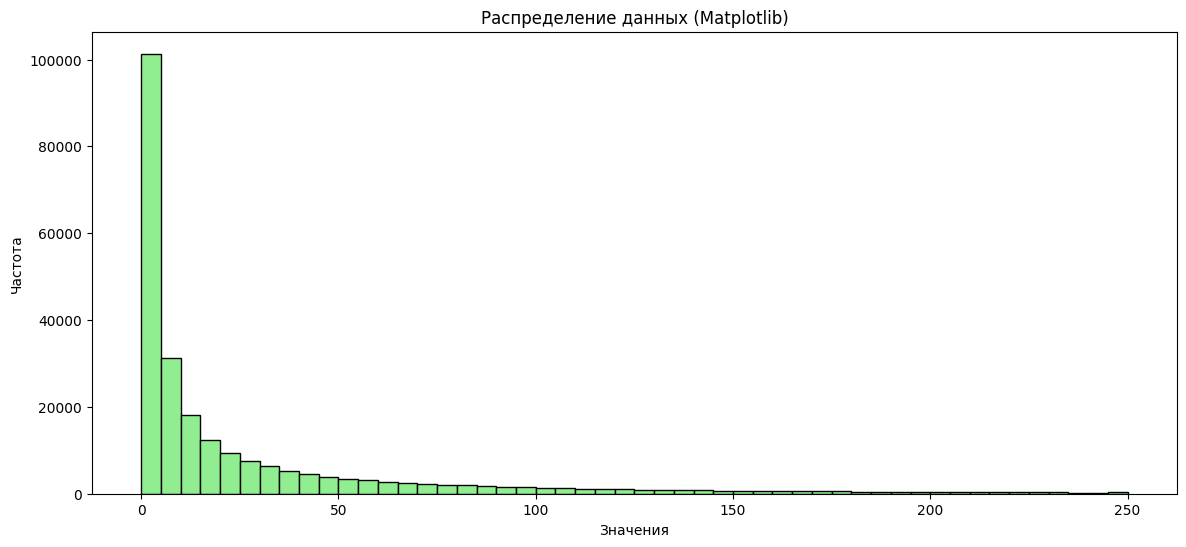

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# Строим график распределения
plt.figure(figsize=(14, 6))
plt.hist(pred_series.filter(pred_series < 250).to_numpy(), bins=50, color='lightgreen', edgecolor='black')
plt.title('Распределение данных (Matplotlib)')
plt.xlabel('Значения')
plt.ylabel('Частота')
plt.show()

In [56]:
internal_importances = model.get_feature_importance()

feature_importance = pl.DataFrame({
    "feature": model.feature_names_,
    "importance": internal_importances
}).sort("importance")

print(feature_importance)

shape: (111, 2)
┌──────────────────────────┬────────────┐
│ feature                  ┆ importance │
│ ---                      ┆ ---        │
│ str                      ┆ f64        │
╞══════════════════════════╪════════════╡
│ gmv_cat_sum_7d           ┆ 0.003347   │
│ to_ord_sum_7d            ┆ 0.003347   │
│ active_days_14d          ┆ 0.006353   │
│ has_search_to_ord_sum_7d ┆ 0.006526   │
│ gmv_cat_mean_7d          ┆ 0.006776   │
│ …                        ┆ …          │
│ searches_sum_7d          ┆ 3.909848   │
│ searches_sum_14d         ┆ 4.48174    │
│ gmv_sum_90d              ┆ 6.81394    │
│ to_ord_sum_90d           ┆ 17.636323  │
│ active_days_90d          ┆ 24.464202  │
└──────────────────────────┴────────────┘


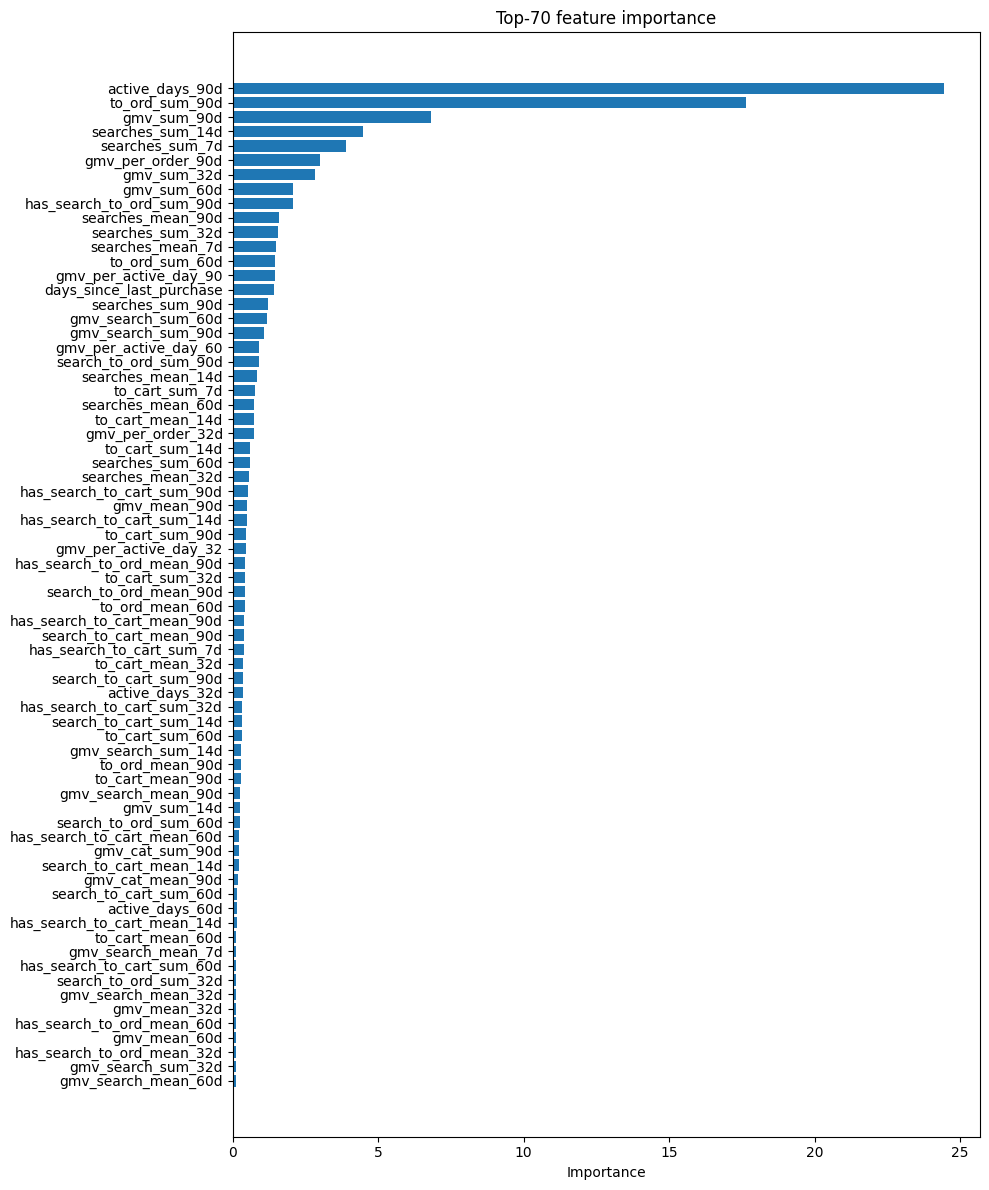

In [64]:
import matplotlib.pyplot as plt

top_n = 70

top = feature_importance.sort("importance", descending=True).head(top_n)
plt.figure(figsize=(10, 12))
plt.barh(top["feature"].to_list(), top["importance"].to_numpy())
plt.gca().invert_yaxis()
plt.title(f"Top-{top_n} feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [65]:
zero_features = (
    feature_importance
    .filter(pl.col("importance") <= 0)
    .get_column("feature")
    .to_list()
)

print("Zero importance features:")
zero_features

Zero importance features:


[]

In [66]:
threshold = 0.99

selected_features = (
    feature_importance
    .filter(pl.col("importance") < threshold)
    .get_column("feature")
    .to_list()
)

# Добавим первый признак, который перешагнул порог,
# чтобы не потерять слишком много важности
if len(selected_features) < feature_importance.height:
    next_feature = feature_importance.slice(len(selected_features), 1).get_column("feature")[0]
    selected_features.append(next_feature)

print("Features before:", len(feature_cols))
print("Features after: ", len(selected_features))
selected_features

Features before: 111
Features after:  94


['gmv_cat_sum_7d',
 'to_ord_sum_7d',
 'active_days_14d',
 'has_search_to_ord_sum_7d',
 'gmv_cat_mean_7d',
 'search_to_ord_sum_7d',
 'search_to_ord_mean_7d',
 'has_search_to_ord_sum_14d',
 'active_days_7d',
 'search_to_ord_mean_14d',
 'to_ord_sum_14d',
 'has_search_to_ord_sum_32d',
 'search_to_ord_sum_14d',
 'gmv_cat_mean_14d',
 'search_to_cart_mean_7d',
 'gmv_mean_7d',
 'to_ord_mean_14d',
 'to_ord_mean_7d',
 'gmv_search_sum_7d',
 'gmv_cat_sum_14d',
 'search_to_cart_sum_7d',
 'gmv_cat_mean_32d',
 'gmv_search_mean_14d',
 'search_to_ord_mean_32d',
 'to_cart_mean_7d',
 'has_search_to_ord_mean_14d',
 'gmv_mean_14d',
 'to_ord_sum_32d',
 'search_to_cart_sum_32d',
 'gmv_cat_mean_60d',
 'gmv_cat_sum_32d',
 'search_to_cart_mean_32d',
 'has_search_to_ord_mean_7d',
 'gmv_cat_sum_60d',
 'has_search_to_cart_mean_32d',
 'has_search_to_cart_mean_7d',
 'search_to_ord_mean_60d',
 'has_search_to_ord_sum_60d',
 'search_to_cart_mean_60d',
 'to_ord_mean_32d',
 'gmv_sum_7d',
 'gmv_search_mean_60d',
 'gmv_sea